# Proyek UTS: Klasifikasi Kondisi Ruangan

**Fitur:** suhu, kelembapan, intensitas cahaya  
**Model baseline:** Decision Tree  
**Sumber data:** simulasi; bukan pengukuran sensor nyata.

Definisi label operasional: Nyaman jika semua parameter berada pada rentang target; Kurang Nyaman jika satu parameter di luar rentang; Tidak Nyaman jika dua atau lebih parameter di luar rentang. Rentang target simulasi: suhu 22–28 °C, kelembapan 40–65% RH, cahaya 300–700 lux.

In [2]:
%pip install pandas numpy matplotlib scikit-learn joblib

Note: you may need to restart the kernel to use updated packages.


In [3]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn joblib

Note: you may need to restart the kernel to use updated packages.


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

DATA_PATH = "dataset_simulasi_kondisi_ruangan.csv"
df = pd.read_csv(DATA_PATH)
fitur = ["suhu", "kelembapan", "cahaya"]
target = "kondisi_ruangan"
print("Ukuran dataset:", df.shape)
display(df.head())
print("\nMissing values:")
print(df[fitur].isna().sum())
print("\nDistribusi kelas:")
print(df[target].value_counts())

Ukuran dataset: (600, 5)


,id_data,suhu,kelembapan,cahaya,kondisi_ruangan
0,1,26.313395,51.280963,643.207634,Nyaman
1,2,26.072440,44.386771,693.323612,Nyaman
2,3,26.619472,58.627960,354.441651,Nyaman
3,4,25.098817,49.473158,667.765232,Nyaman
4,5,25.918686,59.769383,471.545090,Nyaman



Missing values:
suhu          12
kelembapan    12
cahaya        12
dtype: int64

Distribusi kelas:
kondisi_ruangan
Kurang Nyaman    210
Tidak Nyaman     201
Nyaman           189
Name: count, dtype: int64


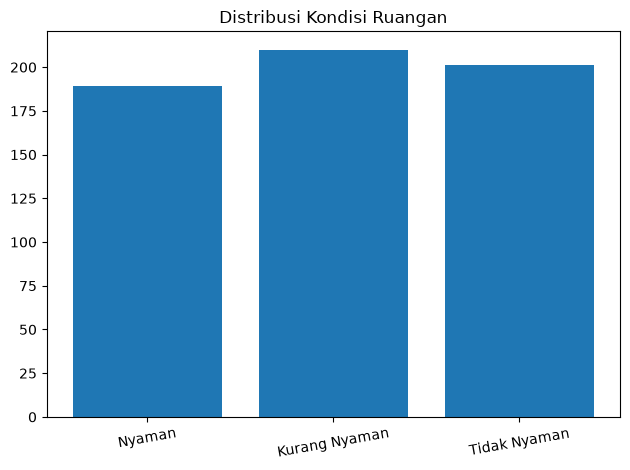

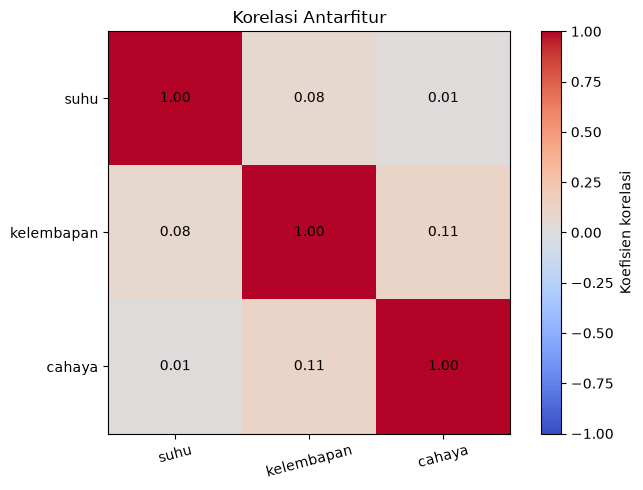

In [5]:
kelas_urut = ["Nyaman", "Kurang Nyaman", "Tidak Nyaman"]
jumlah_kelas = df[target].value_counts().reindex(kelas_urut, fill_value=0)
plt.bar(jumlah_kelas.index, jumlah_kelas.values)
plt.title("Distribusi Kondisi Ruangan")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

korelasi = df[fitur].corr()
plt.figure(figsize=(7, 5))
plt.imshow(korelasi, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Koefisien korelasi")
plt.xticks(range(len(fitur)), fitur, rotation=15)
plt.yticks(range(len(fitur)), fitur)
for i in range(len(fitur)):
    for j in range(len(fitur)):
        plt.text(j, i, f"{korelasi.iloc[i, j]:.2f}", ha="center", va="center")
plt.title("Korelasi Antarfitur")
plt.tight_layout()
plt.show()

In [6]:
X = df[fitur]
y = df[target]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

model = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", DecisionTreeClassifier(
        criterion="gini", max_depth=5, min_samples_leaf=4, random_state=42
    ))
])
model.fit(X_train, y_train)
print("Training:", len(X_train), "Testing:", len(X_test))

Training: 480 Testing: 120


Accuracy: 0.8917
               precision    recall  f1-score   support

Kurang Nyaman       0.94      0.74      0.83        42
       Nyaman       0.78      1.00      0.87        38
 Tidak Nyaman       1.00      0.95      0.97        40

     accuracy                           0.89       120
    macro avg       0.90      0.90      0.89       120
 weighted avg       0.91      0.89      0.89       120



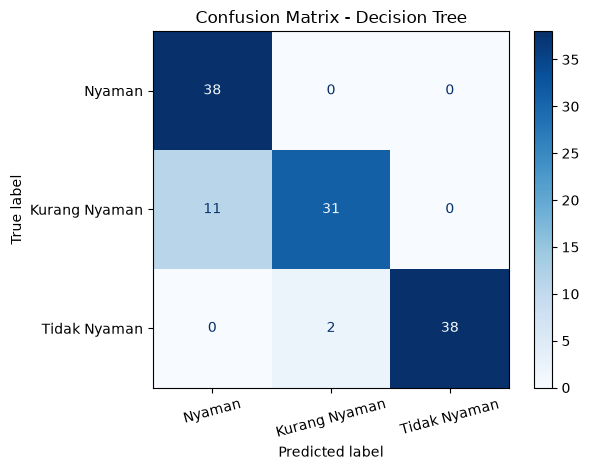

In [7]:
y_pred = model.predict(X_test)
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print(classification_report(y_test, y_pred, zero_division=0))
labels = ["Nyaman", "Kurang Nyaman", "Tidak Nyaman"]
ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix(y_test, y_pred, labels=labels),
    display_labels=labels
).plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - Decision Tree")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

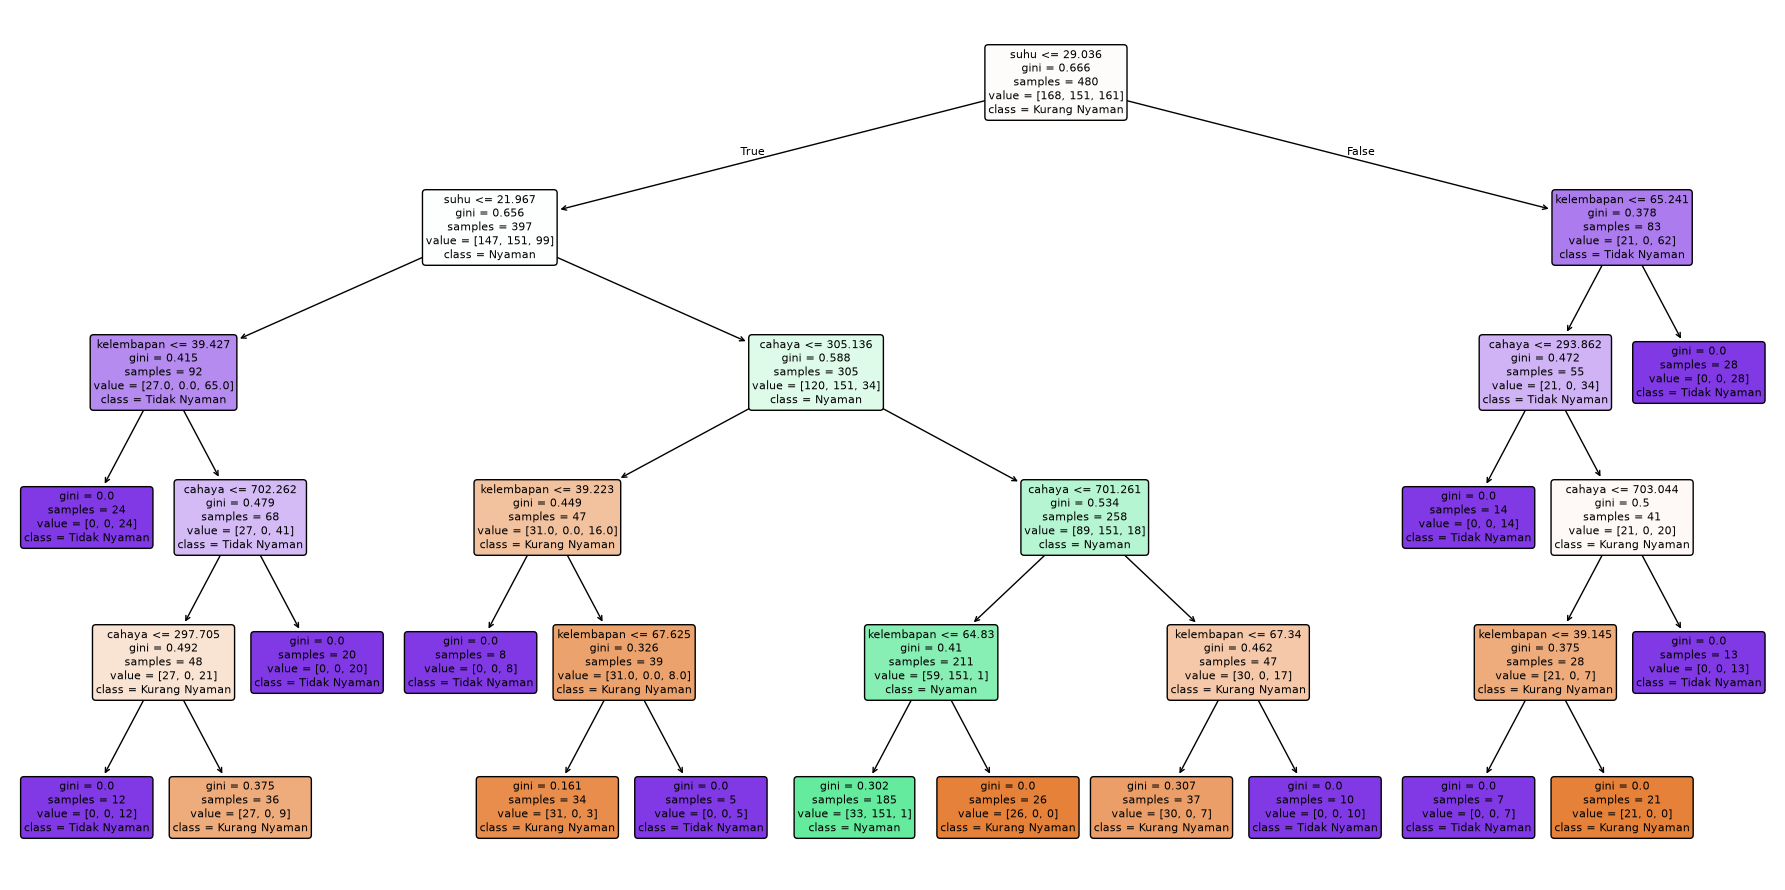

,feature_importance
cahaya,0.361936
kelembapan,0.334311
suhu,0.303753


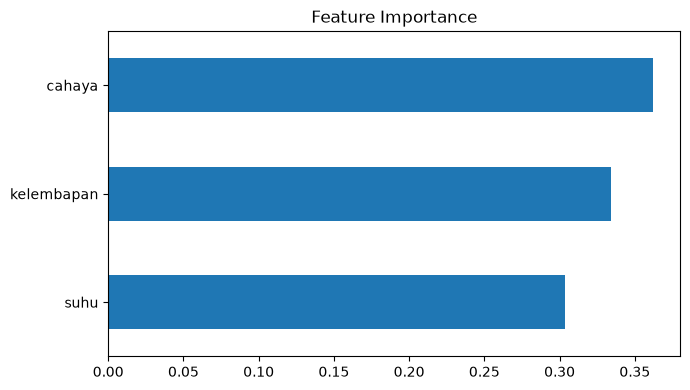

In [8]:
plt.figure(figsize=(18, 9))
plot_tree(model.named_steps["classifier"], feature_names=fitur,
          class_names=model.named_steps["classifier"].classes_,
          filled=True, rounded=True, fontsize=8)
plt.tight_layout()
plt.show()

importance = pd.Series(model.named_steps["classifier"].feature_importances_, index=fitur).sort_values(ascending=False)
display(importance.to_frame("feature_importance"))
importance.sort_values().plot(kind="barh", figsize=(7, 4))
plt.title("Feature Importance")
plt.tight_layout()
plt.show()

In [9]:
data_baru = pd.DataFrame([{"suhu": 26.0, "kelembapan": 55.0, "cahaya": 450.0}])
print("Prediksi:", model.predict(data_baru)[0])
joblib.dump(model, "model_kondisi_ruangan.joblib")
print("Model disimpan.")

Prediksi: Nyaman
Model disimpan.
